# 02 — Correlación entre voto y variables sociodemográficas

Exploramos la asociación entre el comportamiento electoral municipal y los indicadores socioeconómicos del CONAPO (Censo 2020), usando correlaciones de **Pearson** (lineal) y **Spearman** (monótona, robusta a valores extremos).

In [1]:
import sys, os
sys.path.insert(0, os.path.join("..", "src"))
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

BASE = os.path.join("..")
PROCESADOS = os.path.join(BASE, "data", "processed")
FIGURAS = os.path.join(BASE, "figuras")
os.makedirs(FIGURAS, exist_ok=True)

df = pd.read_csv(os.path.join(PROCESADOS, "municipios_electoral_social.csv"),
                 dtype={"cvegeo": str})
gdf = gpd.read_file(os.path.join(PROCESADOS, "municipios_cartografia_simplificada.gpkg"))
gdf["cvegeo"] = gdf["cvegeo"].str.zfill(5)
gdf = gdf.merge(df, on="cvegeo", how="left")
print(f"{len(df)} municipios con datos, {len(gdf)} polígonos")
gdf.head(3)
from scipy import stats

VARS_SOCIALES = {
    "pct_analfabeta": "Analfabetismo (%)",
    "pct_sin_basica": "Sin educación básica (%)",
    "pct_sin_drenaje": "Sin drenaje (%)",
    "pct_sin_electricidad": "Sin electricidad (%)",
    "pct_sin_agua": "Sin agua entubada (%)",
    "pct_piso_tierra": "Piso de tierra (%)",
    "pct_hacinamiento": "Hacinamiento (%)",
    "pct_rural": "Población en localidades <5,000 hab (%)",
    "pct_ingresos_bajos": "Ingresos < 2 salarios mínimos (%)",
    "im_2020": "Índice de marginación",
    "pob_total": "Población total (log)",
}
VARS_ELECTORALES = {
    "pct_sheinbaum": "% Sheinbaum",
    "pct_galvez": "% Gálvez",
    "pct_maynez": "% Máynez",
    "pct_participacion": "% Participación",
}
d = df.dropna(subset=list(VARS_ELECTORALES)).copy()
d["pob_total"] = np.log10(d["pob_total"])


2469 municipios con datos, 2478 polígonos


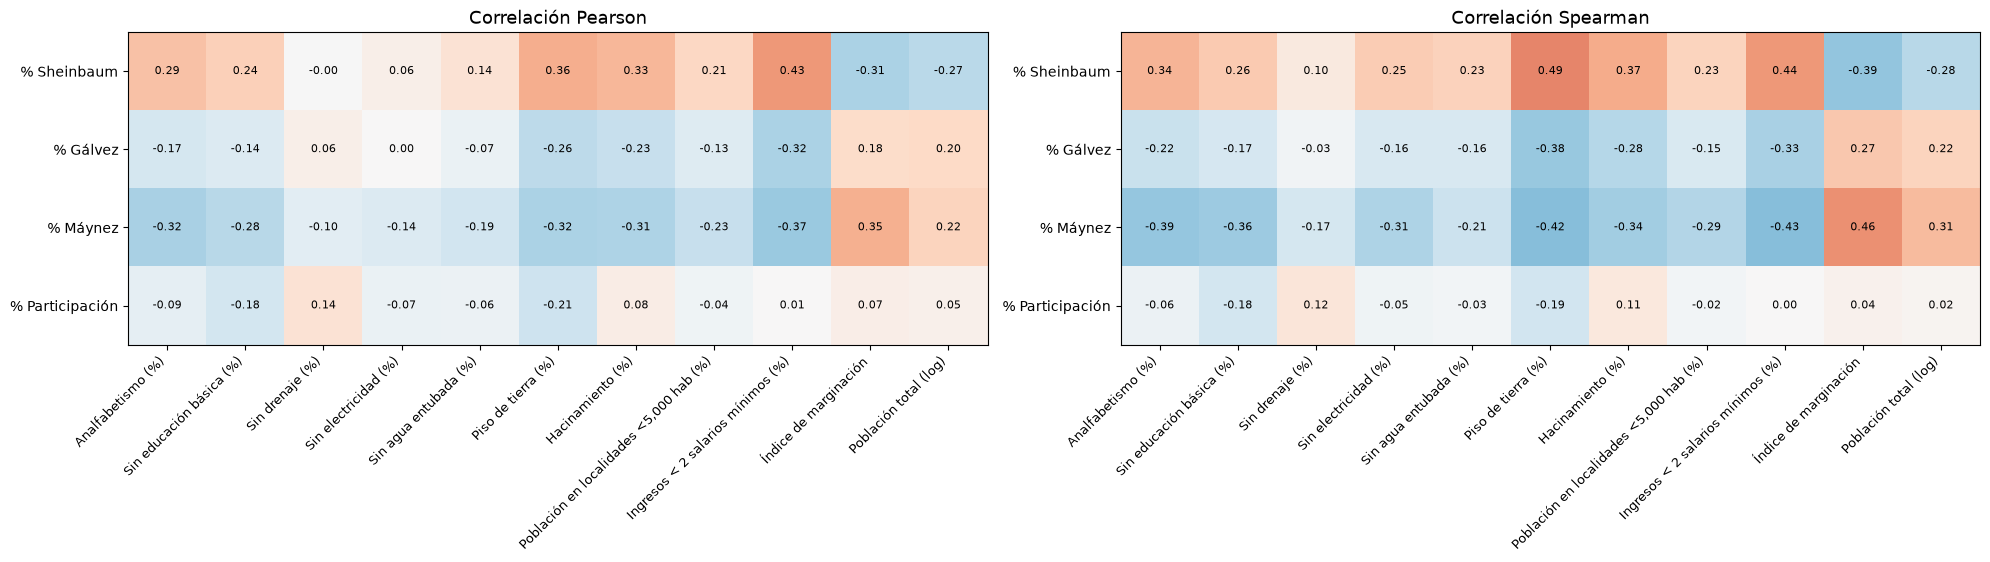

In [2]:
vars_analizar = list(VARS_ELECTORALES) + list(VARS_SOCIALES)
corr_p = d[vars_analizar].corr(method="pearson")
corr_s = d[vars_analizar].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, corr, nombre in zip(axes, [corr_p, corr_s], ["Pearson", "Spearman"]):
    sub = corr.loc[list(VARS_ELECTORALES), list(VARS_SOCIALES)]
    im = ax.imshow(sub, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(sub.columns)))
    ax.set_xticklabels([VARS_SOCIALES[c] for c in sub.columns], rotation=45, ha="right", fontsize=9)
    ax.set_yticks(range(len(sub.index)))
    ax.set_yticklabels([VARS_ELECTORALES[v] for v in sub.index], fontsize=10)
    for i in range(sub.shape[0]):
        for j in range(sub.shape[1]):
            ax.text(j, i, f"{sub.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="black")
    ax.set_title(f"Correlación {nombre}", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, "heatmap_correlaciones.png"), dpi=150, bbox_inches="tight")
plt.show()

In [3]:
tabla = []
for v_elec in VARS_ELECTORALES:
    for v_soc in VARS_SOCIALES:
        r, p = stats.pearsonr(d[v_elec], d[v_soc])
        rho, ps = stats.spearmanr(d[v_elec], d[v_soc])
        tabla.append({"variable_electoral": VARS_ELECTORALES[v_elec],
                      "variable_social": VARS_SOCIALES[v_soc],
                      "pearson_r": r, "pearson_p": p,
                      "spearman_rho": rho, "spearman_p": ps})
tabla = pd.DataFrame(tabla)
print("Correlaciones más fuertes con % Sheinbaum (en valor absoluto):")
display(tabla[tabla.variable_electoral == "% Sheinbaum"]
        .reindex(tabla[tabla.variable_electoral == "% Sheinbaum"].spearman_rho.abs()
                 .sort_values(ascending=False).index)
        .round(3).head(12))
print("Correlaciones más fuertes con % Participación:")
display(tabla[tabla.variable_electoral == "% Participación"]
        .reindex(tabla[tabla.variable_electoral == "% Participación"].spearman_rho.abs()
                 .sort_values(ascending=False).index)
        .round(3).head(12))

Correlaciones más fuertes con % Sheinbaum (en valor absoluto):


,variable_electoral,variable_social,pearson_r,pearson_p,spearman_rho,spearman_p
5,% Sheinbaum,Piso de tierra (%),0.360,0.000,0.485,0.0
8,% Sheinbaum,Ingresos < 2 salarios mínimos (%),0.435,0.000,0.437,0.0
9,% Sheinbaum,Índice de marginación,-0.314,0.000,-0.394,0.0
6,% Sheinbaum,Hacinamiento (%),0.332,0.000,0.370,0.0
0,% Sheinbaum,Analfabetismo (%),0.290,0.000,0.337,0.0
10,% Sheinbaum,Población total (log),-0.268,0.000,-0.279,0.0
1,% Sheinbaum,Sin educación básica (%),0.238,0.000,0.261,0.0
3,% Sheinbaum,Sin electricidad (%),0.057,0.005,0.253,0.0
4,% Sheinbaum,Sin agua entubada (%),0.141,0.000,0.229,0.0
7,% Sheinbaum,"Población en localidades <5,000 hab (%)",0.208,0.000,0.226,0.0


Correlaciones más fuertes con % Participación:


,variable_electoral,variable_social,pearson_r,pearson_p,spearman_rho,spearman_p
38,% Participación,Piso de tierra (%),-0.207,0.000,-0.192,0.000
34,% Participación,Sin educación básica (%),-0.181,0.000,-0.183,0.000
35,% Participación,Sin drenaje (%),0.141,0.000,0.118,0.000
39,% Participación,Hacinamiento (%),0.078,0.000,0.108,0.000
33,% Participación,Analfabetismo (%),-0.091,0.000,-0.057,0.005
36,% Participación,Sin electricidad (%),-0.066,0.001,-0.046,0.022
42,% Participación,Índice de marginación,0.069,0.001,0.044,0.031
37,% Participación,Sin agua entubada (%),-0.058,0.004,-0.029,0.149
40,% Participación,"Población en localidades <5,000 hab (%)",-0.042,0.035,-0.024,0.226
43,% Participación,Población total (log),0.053,0.008,0.024,0.226


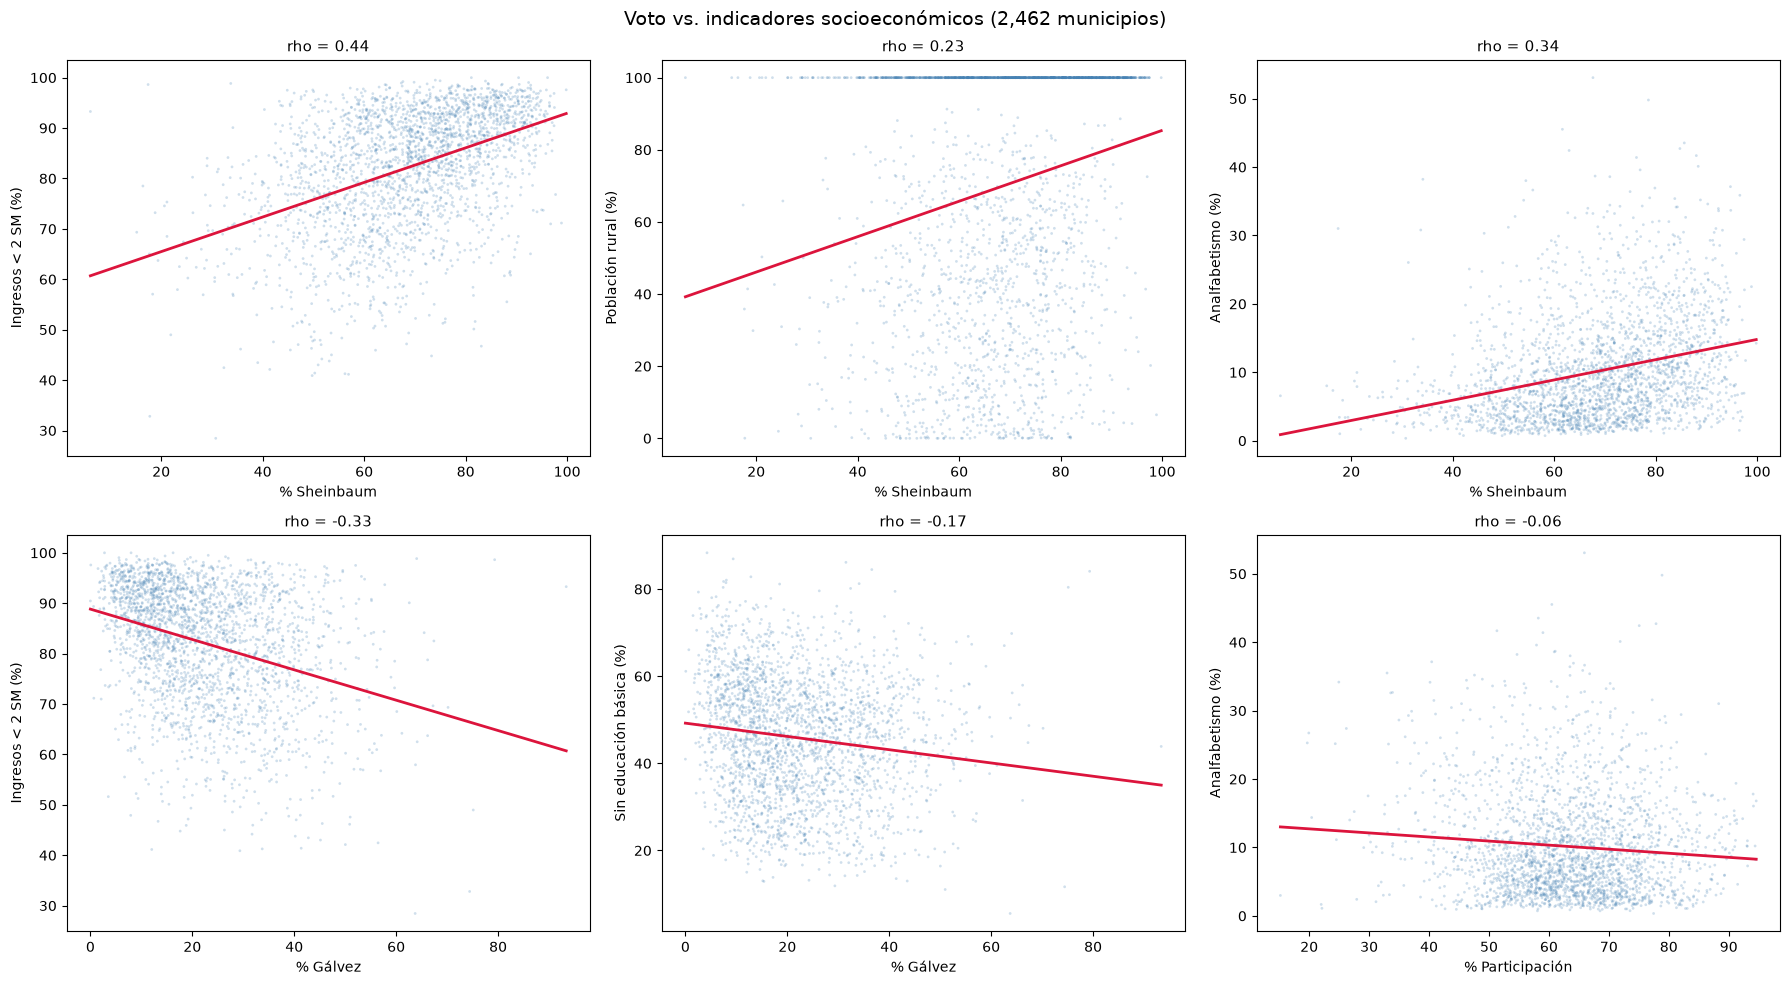

In [4]:
from matplotlib.colors import TwoSlopeNorm

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
pares = [("pct_sheinbaum", "pct_ingresos_bajos", "% Sheinbaum", "Ingresos < 2 SM (%)"),
         ("pct_sheinbaum", "pct_rural", "% Sheinbaum", "Población rural (%)"),
         ("pct_sheinbaum", "pct_analfabeta", "% Sheinbaum", "Analfabetismo (%)"),
         ("pct_galvez", "pct_ingresos_bajos", "% Gálvez", "Ingresos < 2 SM (%)"),
         ("pct_galvez", "pct_sin_basica", "% Gálvez", "Sin educación básica (%)"),
         ("pct_participacion", "pct_analfabeta", "% Participación", "Analfabetismo (%)")]
for ax, (x, y, lx, ly) in zip(axes.flat, pares):
    rho, _ = stats.spearmanr(d[x], d[y])
    ax.scatter(d[x], d[y], s=4, alpha=0.25, color="steelblue", edgecolor="none")
    z = np.polyfit(d[x], d[y], 1)
    xs = np.linspace(d[x].min(), d[x].max(), 50)
    ax.plot(xs, np.polyval(z, xs), color="crimson", lw=2)
    ax.set_xlabel(lx, fontsize=10)
    ax.set_ylabel(ly, fontsize=10)
    ax.set_title(f"rho = {rho:.2f}", fontsize=11)
plt.suptitle("Voto vs. indicadores socioeconómicos (2,462 municipios)", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, "scatter_voto_social.png"), dpi=150, bbox_inches="tight")
plt.show()